# Predicting TFT Placement from the Final Board (Set 18)

Can a player's end-of-game board (champions, star levels, items, traits) predict their placement
(1st to 8th)? Data: **39,745 ranked EUW matches** from Set 18 (patch 18.1, 26 Aug to 7 Sep 2026),
collected with the Riot API, plus 9,908 later matches (18.3) used as an out-of-patch test.

**Key results**

- A gradient-boosted model reaches a test MAE of **1.17 places** (2.00 for always predicting the
  mean) and gets top 4 right 82% of the time.
- **Five board-size counters alone achieve a lower MAE than the full model (1.09 vs. 1.17).** This
  suggests that much of the predictive signal comes from board size rather than the detailed
  composition.
- Adding three of these counters to the full model lowers MAE to **0.96**, against 1.09 for the
  counters alone. This suggests that the composition carries some information beyond board size,
  although the gain is small (0.13 places) and does not establish a causal effect. On patch 18.3 the
  gap is 0.11 (1.01 vs. 1.12), and the full model degrades more than the counters (1.27 vs. 1.12).
- Players on the same archetype in a lobby place worse: +0.30 places per extra player in raw terms,
  but only **+0.04** within a match at equal board size.
- The worst errors concentrate on one archetype that usually loses but sometimes wins.

Applying the same pipeline to Set 17 ([Set 17 notebook](tft_placement_analysis.ipynb)) gives a
similar overall accuracy (MAE 1.18), contest effect and failure mode. The board-size baselines were
not run there, so it doesn't show whether board size dominates on Set 17 too, nor that the model has
learned composition patterns that transfer across sets.

**Contents:** 1. Context · 2. Data and quality checks · 3. Archetypes · 4. Contest ·
5. Features and leakage · 6. Model and evaluation · 7. SHAP · 8. Error analysis · 9. Conclusions

> **Reproducibility.** The logic lives in `src/`; this notebook calls it. The analysis is frozen on
> matches played before 8 September (`STUDY_END`, `src/set_paths.py`); the database also holds
> later matches, used only in Section 6.3.

## 1. Context

TFT is an 8-player auto-battler. Each player builds a board of champions, traits and items from a
shared pool, the boards fight automatically, and placement (1st to 8th) is the elimination order.
Set 18 launched on 26 August 2026 on a new engine: all champions and traits are new, `character_id`
names changed, and some API fields are no longer filled (Section 2).

**Questions**

1. How well does the final board predict placement, and how much of that is just board size?
2. Do players on the same archetype hurt each other, at equal board size?
3. Which features does the model rely on?
4. Where does it fail?

In [1]:
import os
import sys
import warnings
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd() / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from db import get_engine
from set_paths import feature_matrix_path, set_suffixed_path, study_end_ms

warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

pd.set_option("display.max_rows", 40)
pd.set_option("display.max_colwidth", 100)

RANDOM_STATE = 42
# Study window: Set 18 matches up to 7 September (patch 18.1). Later matches,
# collected afterwards, are only used in Section 6.3.
STUDY_END = study_end_ms()

TIER_ORDER = ["IRON", "BRONZE", "SILVER", "GOLD", "PLATINUM", "EMERALD",
              "DIAMOND", "MASTER", "GRANDMASTER", "CHALLENGER"]

# --- chart styling (same palette as the project's existing notebooks) ---
COLOR_BLUE = "#2a78d6"
COLOR_RED = "#e34948"
COLOR_GREEN = "#3f9142"
COLOR_MUTED = "#898781"
COLOR_GRID = "#e1e0d9"
COLOR_TEXT = "#0b0b0b"
COLOR_TEXT_SECONDARY = "#52514e"

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": COLOR_MUTED,
    "axes.labelcolor": COLOR_TEXT_SECONDARY,
    "xtick.color": COLOR_MUTED,
    "ytick.color": COLOR_MUTED,
    "text.color": COLOR_TEXT,
    "font.size": 10,
    "grid.color": COLOR_GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})

engine = get_engine()
print("Connected to", Path(engine.url.database).name)

Connected to tft_set18.db


## 2. Data and quality checks

Matches come from `src/ingest_matches.py`: for each tier, seed players are taken from the ladder and
their recent ranked matches (`queue_id` 1100) are downloaded. One row is one player in one match
(8 per match). `seed_tier` is the seed player's tier, copied to the whole lobby; the other seven
players' ranks are unknown. The sample is ladder-based, not random.

### 2.1 Structure and bots

In [2]:
in_window = f"game_datetime < {STUDY_END}"
missing = pd.DataFrame({
    "matches": pd.read_sql(f"SELECT * FROM matches WHERE {in_window}", engine).isna().sum(),
}).query("matches > 0")
print("Columns in `matches` with any NULLs:")
print(missing if not missing.empty else "  none")

participants_df = pd.read_sql(f"""
    SELECT p.* FROM participants p JOIN matches m ON m.match_id = p.match_id
    WHERE m.{in_window}
""", engine)
missing_p = participants_df.isna().sum()
missing_p = missing_p[missing_p > 0]
print("\nColumns in `participants` with any NULLs:")
print(missing_p if not missing_p.empty else "  none")

print(f"\nExactly 8 participants per match: "
      f"{(participants_df.groupby('match_id').size() == 8).all()}")

dup_mask = participants_df.duplicated(subset=["match_id", "puuid"], keep=False)
print(f"Duplicate participant rows (same match_id + puuid): "
      f"{participants_df.duplicated(subset=['match_id', 'puuid']).sum()}")
print(f"Placement values outside 1-8: "
      f"{((participants_df['placement'] < 1) | (participants_df['placement'] > 8)).sum()}")

dup_puuids = sorted(participants_df.loc[dup_mask, "puuid"].unique())
print(f"\nDistinct puuid values involved in the duplicate rows: {dup_puuids}")

is_bot = participants_df["puuid"] == "BOT"
n_bots = int(is_bot.sum())
n_human_participants = int(len(participants_df) - n_bots)
print(f"Participant rows with puuid == 'BOT': {n_bots:,} "
      f"across {participants_df.loc[is_bot, 'match_id'].nunique():,} matches")
print(f"Human participants once bots are excluded: {n_human_participants:,}")

bot_tier = pd.read_sql(f'''
    SELECT m.seed_tier,
           COUNT(*) AS total_rows,
           SUM(CASE WHEN p.puuid = 'BOT' THEN 1 ELSE 0 END) AS bot_rows
    FROM participants p JOIN matches m ON m.match_id = p.match_id
    WHERE m.{in_window}
    GROUP BY m.seed_tier
''', engine)
# Rate, not raw count: tiers have very different total volumes (Emerald has 8x
# Iron's match count), so a raw bot-row count mostly just reflects tier size.
bot_tier["bot_rate_pct"] = (bot_tier["bot_rows"] / bot_tier["total_rows"] * 100).round(2)
print("\nBot rate by seed_tier:")
print(bot_tier.sort_values("bot_rate_pct", ascending=False).to_string(index=False))

Columns in `matches` with any NULLs:
  none



Columns in `participants` with any NULLs:
  none

Exactly 8 participants per match: True
Duplicate participant rows (same match_id + puuid): 2428
Placement values outside 1-8: 0

Distinct puuid values involved in the duplicate rows: ['BOT']
Participant rows with puuid == 'BOT': 3,186 across 758 matches
Human participants once bots are excluded: 314,774



Bot rate by seed_tier:
  seed_tier  total_rows  bot_rows  bot_rate_pct
     BRONZE       10272       301          2.93
     SILVER       21264       397          1.87
       GOLD       34992       619          1.77
       IRON        6184        81          1.31
   PLATINUM       55928       648          1.16
    EMERALD       70168       688          0.98
    DIAMOND       54616       292          0.53
GRANDMASTER       20792        84          0.40
     MASTER       30664        64          0.21
 CHALLENGER       13080        12          0.09


No missing values and exactly 8 rows per match. The only duplicates have `puuid == 'BOT'`: Riot fills
incomplete lobbies with bots (3,186 rows in 758 matches, 1.0%, from 2.9% in Bronze to 0.1% in
Challenger). They are excluded everywhere, which leaves **314,774 human rows**.

### 2.2 No patch number

In [3]:
from features.build_feature_matrix import extract_patch

versions = pd.read_sql("SELECT DISTINCT game_version FROM matches", engine)
print("distinct game_version values in this dataset:")
print(versions["game_version"].tolist())
print("\nwhat extract_patch() returns for it:", repr(extract_patch(versions["game_version"].iloc[0])))

distinct game_version values in this dataset:
['TFT Unreal Version ?.?.?.?']

what extract_patch() returns for it: 'TFT Unreal Version ?.?.?.?'


Every match reports the same placeholder. The patch is therefore inferred from the match date and
Riot's release calendar (`data/external/tft_patch_calendar.csv`). All matches of the study window fall in
18.1, so the train/test split uses dates (6.1).

### 2.3 Empty combat statistics

In [4]:
from features.build_feature_matrix import load_base

base = load_base(engine, end_ms=STUDY_END)

numeric_summary = base[[
    "placement", "level", "gold_left", "last_round",
    "players_eliminated", "time_eliminated", "total_damage_to_players",
]].describe().T
numeric_summary

,count,mean,std,min,25%,50%,75%,max
placement,314774.0,4.481939,2.291726,1.0,2.0,4.0,6.0,8.0
level,314774.0,8.173451,0.920079,4.0,8.0,8.0,9.0,10.0
gold_left,314774.0,9.375971,16.873342,0.0,1.0,2.0,11.0,2065.0
last_round,314774.0,31.302341,4.628788,7.0,28.0,31.0,35.0,45.0
players_eliminated,314774.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
time_eliminated,314774.0,1976.621945,283.208534,370.0,1768.0,1987.0,2188.0,2883.0
total_damage_to_players,314774.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0


In [5]:
import json
import glob
import random

random.seed(1)
sample_files = random.sample(glob.glob("data/raw/*.json"), 200)

checked, nonzero_dmg, nonzero_elim = 0, 0, 0
set18_matches = []
for f in sample_files:
    with open(f, encoding="utf-8") as fh:
        m = json.load(fh)
    if m["info"].get("tft_set_number") != 18:
        continue
    checked += 1
    set18_matches.append(m)
    for p in m["info"]["participants"]:
        nonzero_dmg += p.get("total_damage_to_players", 0) != 0
        nonzero_elim += p.get("players_eliminated", 0) != 0

print(f"Checked {checked} Set 18 matches ({checked * 8} participants) from a random raw-file sample")
print(f"Participants with nonzero total_damage_to_players: {nonzero_dmg}")
print(f"Participants with nonzero players_eliminated: {nonzero_elim}")

winner = next(p for p in set18_matches[0]["info"]["participants"] if p["placement"] == 1)
print(f"\n1st-place finisher's raw values (Set 18 match) -> "
      f"players_eliminated={winner['players_eliminated']}, "
      f"total_damage_to_players={winner['total_damage_to_players']}")

Checked 83 Set 18 matches (664 participants) from a random raw-file sample
Participants with nonzero total_damage_to_players: 0
Participants with nonzero players_eliminated: 0

1st-place finisher's raw values (Set 18 match) -> players_eliminated=0, total_damage_to_players=0


`players_eliminated` and `total_damage_to_players` are 0 for every row, including winners, and also
in the raw JSON: Riot doesn't fill them for Set 18 yet. Both would be excluded as leakage anyway (5.1).

**Other checks**

- Only Set 18 ranked matches are kept: Set 17 games still in players' histories are removed
  (`cleanup_matches.py`).
- One non-player unit (`TFT18_SprykinSummonMelee`, a summon) is excluded; the other 79
  `character_id` values are playable champions.
- Augments are absent from the API payload, so they can't be used.
- All tiers cover the same 12 days, so tier and date are not confounded (they were in Set 17).
- Four `character_id` to champion-name mappings are unconfirmed, which only affects reading SHAP
  results by name.

### 2.4 Placement by tier

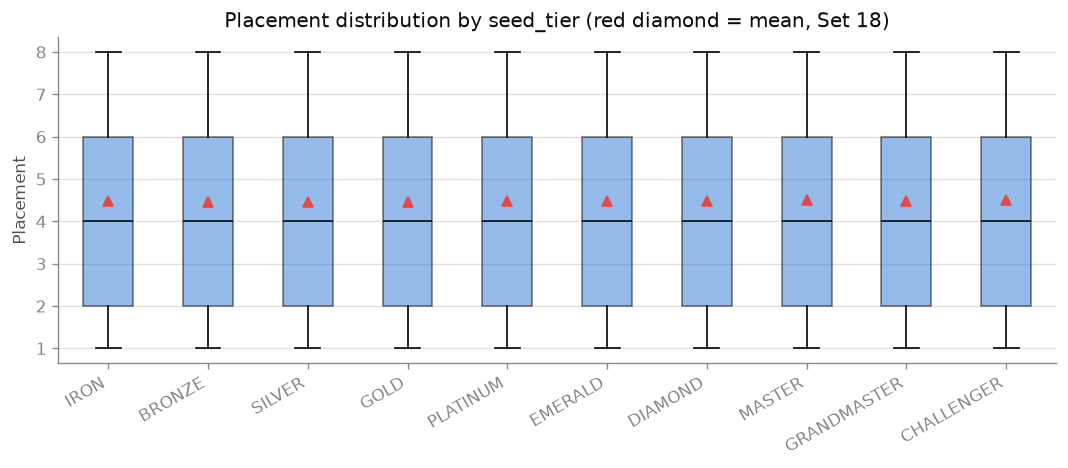

seed_tier
IRON           4.476
BRONZE         4.461
SILVER         4.469
GOLD           4.468
PLATINUM       4.477
EMERALD        4.482
DIAMOND        4.489
MASTER         4.496
GRANDMASTER    4.492
CHALLENGER     4.498
Name: placement, dtype: float64

In [6]:
tier_data = [base.loc[base["seed_tier"] == t, "placement"].values
             for t in TIER_ORDER if t in base["seed_tier"].unique()]
tier_labels = [t for t in TIER_ORDER if t in base["seed_tier"].unique()]

fig, ax = plt.subplots(figsize=(9, 4))
bp = ax.boxplot(tier_data, tick_labels=tier_labels, patch_artist=True, showmeans=True,
                 medianprops={"color": COLOR_TEXT}, meanprops={"markerfacecolor": COLOR_RED, "markeredgecolor": COLOR_RED})
for patch in bp["boxes"]:
    patch.set_facecolor(COLOR_BLUE)
    patch.set_alpha(0.5)
ax.set_ylabel("Placement")
ax.set_title("Placement distribution by seed_tier (red diamond = mean, Set 18)")
ax.grid(axis="y")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

base.groupby("seed_tier")["placement"].mean().reindex(TIER_ORDER).dropna().round(3)

Every tier averages 4.46 to 4.50: each lobby contains places 1 to 8, and the small gaps follow the
bot rate. This comparison can't reveal a skill difference; Section 7.1 asks the question differently.

## 3. Composition archetypes

Players think in comps, not single units. I cluster boards with K-Means on the presence/absence of
each trait and champion (`src/analysis/archetypes.py`). Presence only: star levels and items measure
how well a comp was executed, not which comp it is.

In [7]:
from analysis.archetypes import load_composition_matrix, scan_k, fit_final, describe_cluster, K_CANDIDATES

comp_df, X_comp, comp_cols = load_composition_matrix()
n_traits = sum(c.startswith("trait__") for c in comp_cols)
n_champs = sum(c.startswith("champ__") for c in comp_cols)
print(f"{len(X_comp):,} participants, {len(comp_cols)} composition columns "
      f"({n_traits} traits, {n_champs} champions), binarized to presence/absence")

314,774 participants, 115 composition columns (36 traits, 79 champions), binarized to presence/absence


### 3.1 Choosing k

  k= 8  inertia=  103530.8  silhouette=0.2215


  k=10  inertia=   94025.2  silhouette=0.2446


  k=12  inertia=   85645.1  silhouette=0.2635


  k=15  inertia=   77256.1  silhouette=0.2892


  k=18  inertia=   72860.3  silhouette=0.2952


  k=20  inertia=   70835.3  silhouette=0.2965


  k=22  inertia=   68337.8  silhouette=0.2980


  k=26  inertia=   65541.6  silhouette=0.2770


  k=30  inertia=   63720.6  silhouette=0.2483


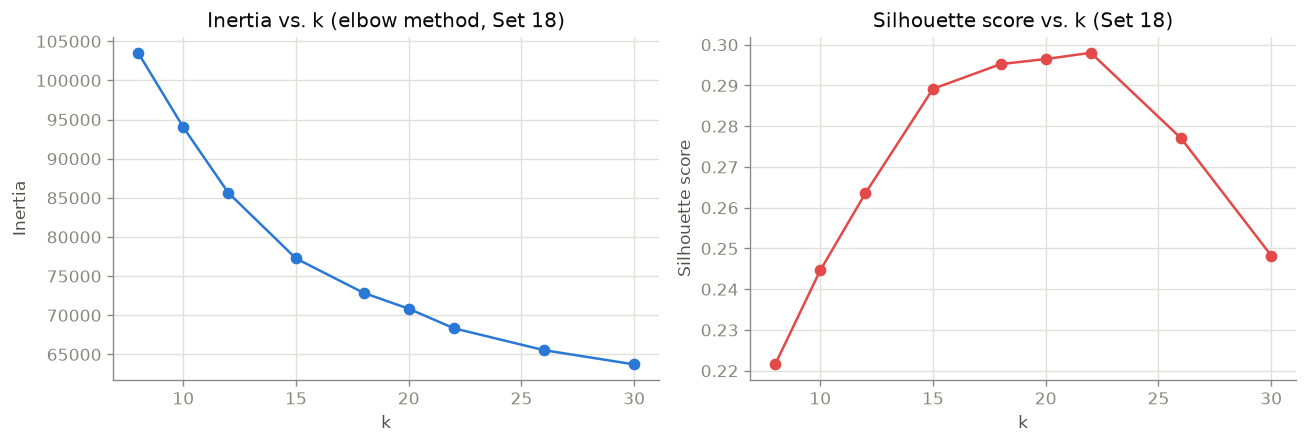

,k,inertia,silhouette
0,8,103530.771436,0.221549
1,10,94025.203774,0.244613
2,12,85645.081660,0.263524
3,15,77256.080196,0.289163
4,18,72860.336501,0.295232
5,20,70835.297491,0.296484
6,22,68337.788233,0.298017
7,26,65541.567371,0.277046
8,30,63720.590163,0.248262


In [8]:
scan_results = scan_k(X_comp, k_candidates=K_CANDIDATES, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(scan_results["k"], scan_results["inertia"], marker="o", color=COLOR_BLUE)
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Inertia vs. k (elbow method, Set 18)")
axes[0].grid(True)

axes[1].plot(scan_results["k"], scan_results["silhouette"], marker="o", color=COLOR_RED)
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette score vs. k (Set 18)")
axes[1].grid(True)

plt.tight_layout()
plt.show()
scan_results

The silhouette stays low for every k (at most 0.30), as expected since comps share many units. I keep
**k = 20** for consistency with Set 17 and check its stability instead: adjusted Rand index between 5
fits on different subsamples and seeds.

In [9]:
from analysis.archetypes import stability_table

# Adjusted Rand index between 5 KMeans fits, each on a different subsample and seed
stability_table(X_comp, k_values=[18, 20, 22]).round(3)

,k,ari_mean,ari_min
0,18,0.929,0.899
1,20,0.919,0.856
2,22,0.890,0.836


k = 20 is stable (mean ARI 0.92, worst pair 0.86). Clusters are renumbered from 0 (best average
placement) to 19 (worst).

### 3.2 The 20 archetypes

In [10]:
km, labels = fit_final(X_comp, k=20, random_state=RANDOM_STATE)

placement_by_raw_id = pd.Series(comp_df["placement"].values).groupby(labels).mean()
rank_of_raw_id = {raw_id: rank for rank, raw_id in enumerate(placement_by_raw_id.sort_values().index)}
labels = pd.Series(labels).map(rank_of_raw_id).to_numpy()

comp_df = comp_df.assign(archetype_cluster=labels)
raw_levels = comp_df[comp_cols]


def clean_name(c):
    return c.replace("DA_18_", "").replace("DA_", "")


archetype_rows = []
for cluster_id in sorted(comp_df["archetype_cluster"].unique()):
    mask = comp_df["archetype_cluster"] == cluster_id
    traits, champs = describe_cluster(comp_df, X_comp, raw_levels, labels, cluster_id,
                                       top_n_traits=5, top_n_champs=6)
    archetype_rows.append({
        "cluster": cluster_id,
        "n": int(mask.sum()),
        "avg_placement": comp_df.loc[mask, "placement"].mean(),
        "core_traits": ", ".join(clean_name(t["name"]) for t in traits[:4]),
        "board": ", ".join(f"{clean_name(c['name'])} ({c['avg_star']:.1f}★)" for c in champs),
    })
archetype_table = pd.DataFrame(archetype_rows).sort_values("avg_placement").reset_index(drop=True)
archetype_table

,cluster,n,avg_placement,core_traits,board
0,0,19046,4.144755,"Adaptor, Juggernaut18, Brawler, Primal18","MasterYi_AD (2.7★), Vi18 (2.5★), Yorick (1.9★), Nidalee18_AP (1.6★), Sett (1.6★), Krug18 (2.2★)"
1,1,14305,4.182733,"Elderwood, Executioner, Maokai_UniqueTrait, Juggernaut18","Ezreal (1.8★), Amumu18 (1.7★), Alistar (1.7★), Kennen (1.5★), GnarSmall (1.5★), Maokai (1.6★)"
2,2,15456,4.238289,"Invoker, Brawler, Spellweaver, Blossom","Sett (1.8★), Ahri (1.9★), Sentinel18 (1.7★), Morgana (1.9★), Krug18 (1.8★), Sentry (1.6★)"
3,3,9296,4.245267,"Juggernaut18, Maokai_UniqueTrait, Vanguard, Emerald18","Amumu18 (1.7★), Maokai (1.5★), Taric18 (1.5★), Kennen (1.5★), Sentinel18 (1.6★), Ivern (1.5★)"
4,4,29989,4.262496,"Riftbeast18, Invoker, Slayer, Brawler","Krug18 (2.4★), Sentry (2.7★), Scuttlecrab18 (2.5★), Sentinel18 (1.6★), Brambleback18 (1.7★), Mur..."
5,5,21382,4.279768,"Defender, FloraFatalis18, Spellweaver","Fiddlesticks18 (2.4★), Rammus (2.4★), Shen (2.0★), Cassiopeia (2.7★), Lillia (1.6★), Ornn (1.9★)"
6,6,14567,4.288048,"Sprykin, Brawler, Spellweaver, Defender","Veigar (2.8★), Kobuko (2.6★), Rammus (2.0★), Fiddlesticks18 (2.0★), Teemo (2.3★), RekSai (2.7★)"
7,7,13309,4.423247,"Primal18, Hunter, Adaptor, Caustic","Sivir (1.9★), Nidalee18_AP (1.9★), KogMaw18_AD (1.8★), Malphite (1.8★), Sentinel18 (1.7★), RekSa..."
8,8,31959,4.447792,"FloraFatalis18, Executioner, Summoner, Blackthorn","Azir (1.8★), Soraka (1.8★), Malphite (1.8★), Zyra (1.8★), Fiddlesticks18 (1.8★), Amumu18 (1.8★)"
9,9,9769,4.484799,"Fae, Defender, Sprykin, Hunter","Tristana (2.5★), Rammus (2.3★), Lillia (1.6★), Rakan (1.9★), Vi18 (2.3★), Sivir (1.6★)"


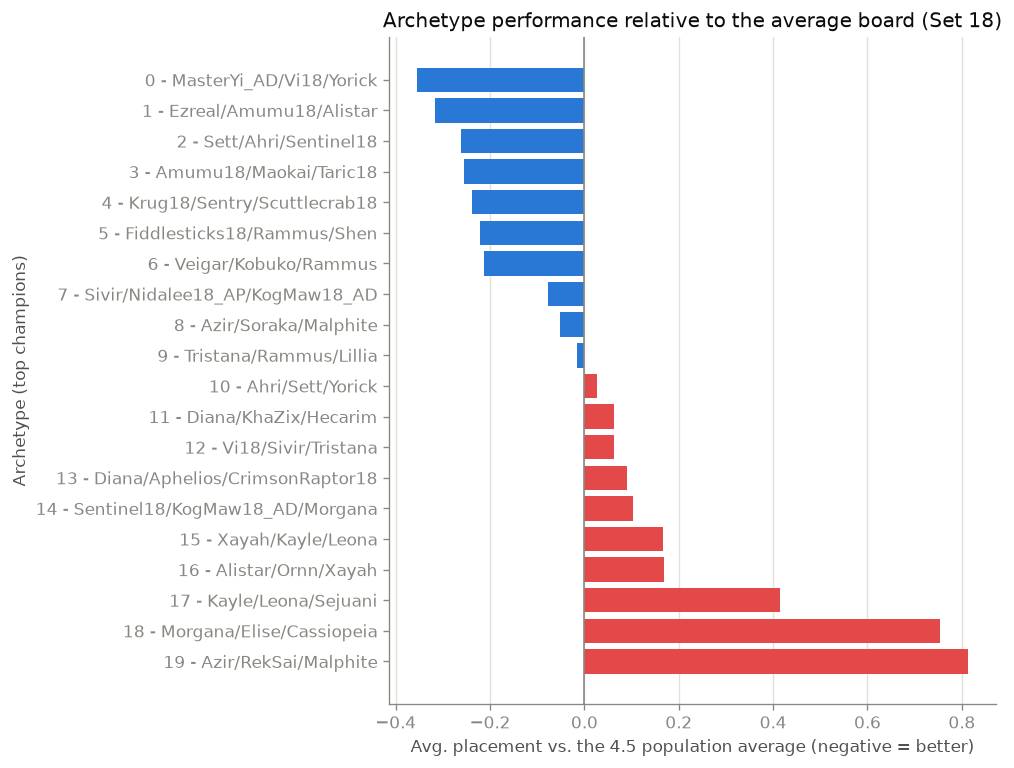

In [11]:
def short_board_label(cluster_id, n=3):
    board = archetype_table.set_index("cluster").loc[cluster_id, "board"]
    names = [c.split(" (")[0] for c in board.split(", ")][:n]
    return f"{cluster_id} - " + "/".join(names)


arch_delta = archetype_table.assign(delta=archetype_table["avg_placement"] - 4.5).sort_values("delta")
bar_labels = [short_board_label(cid) for cid in arch_delta["cluster"]]

fig, ax = plt.subplots(figsize=(8.5, 6.5))
colors = [COLOR_BLUE if d < 0 else COLOR_RED for d in arch_delta["delta"]]
ax.barh(bar_labels, arch_delta["delta"], color=colors)
ax.axvline(0, color=COLOR_MUTED, linewidth=1)
ax.invert_yaxis()
ax.set_xlabel("Avg. placement vs. the 4.5 population average (negative = better)")
ax.set_ylabel("Archetype (top champions)")
ax.set_title("Archetype performance relative to the average board (Set 18)")
ax.grid(axis="x")
plt.tight_layout()
plt.show()

Average placement ranges from 4.14 (cluster 0) to 5.31 (cluster 19). This is not a pure strength
ranking: it also reflects who plays each comp, how contested it is and how long it usually survives.

## 4. Contest

All players buy from a shared pool, so players on the same archetype compete for the same units. A
player's contest level is the number of other players in the lobby assigned to the same cluster.

In [12]:
from analysis.archetypes import save_cluster_assignments
from analysis.archetype_contest import load_data, compute_contest_level, bucket_contest

clusters_path = save_cluster_assignments(comp_df, labels)
print(f"Saved archetype assignments to {clusters_path}")

contest_df = compute_contest_level(load_data())
contest_df["contest_bucket"] = contest_df["contest_level"].apply(bucket_contest)

contest_df["contest_level"].value_counts().sort_index()

Saved archetype assignments to C:\Users\manon\TFT-Analytics\data\processed\archetype_clusters_tft_set18.csv


contest_level
0    216217
1     81180
2     15471
3      1776
4       130
Name: count, dtype: int64

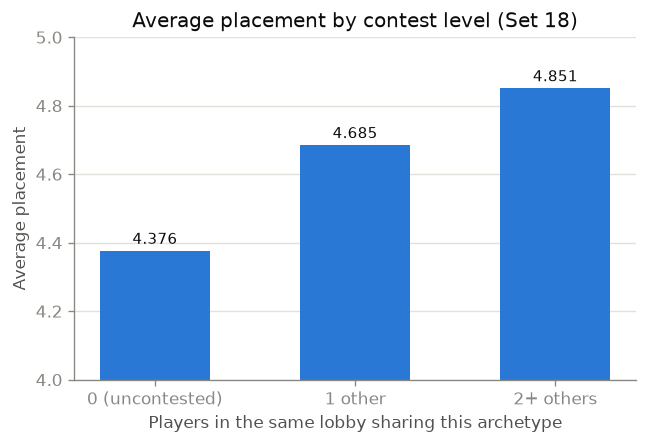

,mean,count
contest_bucket,,
0 (uncontested),4.376085,216217
1 other,4.684898,81180
2+ others,4.850895,17377


In [13]:
bucket_order = ["0 (uncontested)", "1 other", "2+ others"]
overall = contest_df.groupby("contest_bucket")["placement"].agg(["mean", "count"]).reindex(bucket_order)

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.bar(overall.index, overall["mean"], color=COLOR_BLUE, width=0.55)
for i, v in enumerate(overall["mean"]):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center", va="bottom", fontsize=9, color=COLOR_TEXT)
ax.set_ylim(4.0, 5.0)
ax.set_ylabel("Average placement")
ax.set_xlabel("Players in the same lobby sharing this archetype")
ax.set_title("Average placement by contest level (Set 18)")
ax.grid(axis="y")
plt.tight_layout()
plt.show()

overall

Raw placement worsens from 4.38 (uncontested) to 4.68 (one other) and 4.85 (two or more). But
clusters are built from final boards, which also reflect board size. The regression below estimates
the effect of each extra contesting player with archetype fixed effects, then adds board-size controls
(champions, total stars, items) and match fixed effects (comparing players of the same lobby). Full
8-human lobbies only, standard errors clustered by match.

In [14]:
from analysis.archetype_contest import (
    BOARD_SIZE_CONTROLS, add_board_counters, eta_squared, permutation_null, regression_table,
)
from modeling.train_model import FULL_LOBBY_SIZE, humans_per_match

full_lobbies = add_board_counters(
    contest_df[humans_per_match(contest_df) == FULL_LOBBY_SIZE].reset_index(drop=True)
)
for col in BOARD_SIZE_CONTROLS:
    print(f"eta^2 of {col} explained by archetype: {eta_squared(full_lobbies[col], full_lobbies['archetype_cluster']):.3f}")

null = permutation_null(full_lobbies, n_permutations=100, random_state=RANDOM_STATE)
print(f"Placements shuffled within match (100x): coef {null.mean():.4f}, "
      f"95% range [{np.percentile(null, 2.5):.4f}, {np.percentile(null, 97.5):.4f}]")

# Coefficient = placement points per extra contesting player, SE clustered by match
regression_table(full_lobbies).round(4)

eta^2 of n_champ explained by archetype: 0.184
eta^2 of sum_star explained by archetype: 0.168
eta^2 of n_items explained by archetype: 0.019


Placements shuffled within match (100x): coef 0.0011, 95% range [-0.0116, 0.0123]


,specification,coef,se,n
0,cluster FE,0.3000,0.0062,311896
1,cluster FE + board size,-0.0073,0.0048,311896
2,cluster FE + match FE,0.4098,0.0083,311896
3,cluster FE + match FE + board size,0.0400,0.0056,311896


- Raw: **+0.30** places per extra player (+0.41 within a match).
- With board-size controls only, the effect vanishes (-0.007): archetypes differ a lot in board size
  (η² = 0.18 for `n_champ`).
- Within a match at equal board size: **+0.04** (SE 0.006), well outside the ±0.012 range obtained by
  shuffling placements within matches.

Contest has a small but real association with placement. It isn't causal (players pick their comp
partly by watching others), and since contest can itself shrink the final board, 0.04 is probably a
lower bound.

## 5. Features and leakage

`src/features/build_feature_matrix.py` builds one row per player:

| Group | Encoding |
|---|---|
| `trait__*` | active trait tier (0 if inactive) |
| `champ__*` | max star level fielded (0 if absent) |
| `item__*` | count on the board |
| `seed_tier`, `patch` | categorical |
| `level`, `last_round`, `time_eliminated`, `players_eliminated`, `total_damage_to_players`, `gold_left` | in the matrix, **excluded from the model** |

The archetype label isn't a feature, since it is derived from the same columns.

In [15]:
matrix = pd.read_csv(feature_matrix_path())

trait_cols = [c for c in matrix.columns if c.startswith("trait__")]
item_cols = [c for c in matrix.columns if c.startswith("item__")]
champ_cols = [c for c in matrix.columns if c.startswith("champ__")]

print(f"{matrix.shape[0]:,} rows x {matrix.shape[1]} columns")
print(f"  {len(trait_cols)} trait columns, {len(item_cols)} item columns, {len(champ_cols)} champion columns")
print(f"  + context columns: {[c for c in matrix.columns if not c.startswith(('trait__', 'item__', 'champ__'))]}")
matrix.iloc[:3, :12]

314,774 rows x 268 columns
  36 trait columns, 141 item columns, 79 champion columns
  + context columns: ['participant_id', 'match_id', 'placement', 'level', 'gold_left', 'last_round', 'players_eliminated', 'time_eliminated', 'total_damage_to_players', 'seed_tier', 'game_datetime', 'patch']


,participant_id,match_id,placement,level,gold_left,last_round,players_eliminated,time_eliminated,total_damage_to_players,seed_tier,game_datetime,patch
0,1,EUW1_7972573451,1,8,39,34,0,2041.0,0,CHALLENGER,1788512946436,18.1
1,2,EUW1_7972573451,2,9,0,34,0,2036.0,0,CHALLENGER,1788512946436,18.1
2,3,EUW1_7972573451,3,9,0,33,0,1980.0,0,CHALLENGER,1788512946436,18.1


### 5.1 Columns that leak the target

Placement is the elimination order, so `last_round` and `time_eliminated` nearly restate it, and
`level` is partly a consequence of surviving.

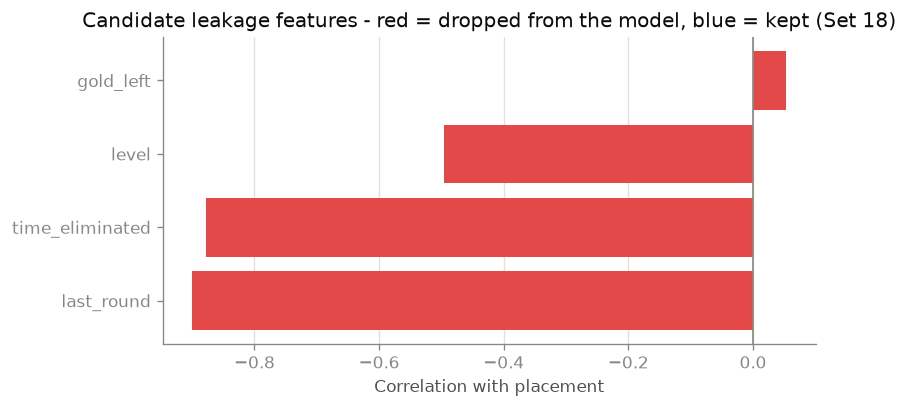

last_round                -0.899682
time_eliminated           -0.877529
level                     -0.495723
gold_left                  0.053434
players_eliminated              NaN
total_damage_to_players         NaN
Name: placement, dtype: float64

In [16]:
from modeling.train_model import DROP_COLS

leak_check = matrix[[
    "placement", "level", "gold_left", "last_round",
    "players_eliminated", "time_eliminated", "total_damage_to_players",
]].corr()["placement"].drop("placement").sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
colors = [COLOR_RED if col in DROP_COLS else COLOR_BLUE for col in leak_check.index]
ax.barh(leak_check.index, leak_check.values, color=colors)
ax.axvline(0, color=COLOR_MUTED, linewidth=1)
ax.set_xlabel("Correlation with placement")
ax.set_title("Candidate leakage features - red = dropped from the model, blue = kept (Set 18)")
ax.grid(axis="x")
plt.tight_layout()
plt.show()

leak_check

The red columns are dropped (`DROP_COLS`). `gold_left` is dropped too, although its correlation with
placement is only 0.05, because of how it is distributed across placements (full lobbies):

In [17]:
from modeling.train_model import FULL_LOBBY_SIZE, humans_per_match

matrix[humans_per_match(matrix) == FULL_LOBBY_SIZE].groupby("placement")["gold_left"].agg(
    mean="mean",
    median="median",
    share_zero=lambda s: (s == 0).mean(),
    share_50_plus=lambda s: (s >= 50).mean(),
).round(3)

,mean,median,share_zero,share_50_plus
placement,,,,
1,11.080,4.0,0.016,0.038
2,6.922,2.0,0.250,0.014
3,8.025,2.0,0.247,0.018
4,8.722,2.0,0.242,0.022
5,8.144,2.0,0.258,0.023
6,8.488,2.0,0.260,0.028
7,9.745,2.0,0.254,0.041
8,13.726,2.0,0.241,0.080


The winner almost never ends at 0 gold (1.6% against about 25% for every other place): the game ends
on their win, so they never have to spend everything to survive one more round. Large leftovers
(50+) are more common in 8th, among players eliminated early. `gold_left` is therefore a trace of
the result, mostly of who won, rather than a measure of economy. (It was kept in the Set 17 model.)

Training the same model without and with the leaky columns shows what the leak looks like:

In [18]:
from modeling.train_model import load_and_prepare, train, report, clip_placement

X_train, y_train, X_test, y_test, train_df, test_df = load_and_prepare()

print("=== Correct model (leakage columns excluded) ===")
model_clean = train(X_train, y_train)
report(y_train, model_clean.predict(X_train), "Train")
report(y_test, model_clean.predict(X_test), "Test (held-out most recent matches)")

=== Correct model (leakage columns excluded) ===



--- Train (n=265104) ---
  MAE: 1.131  (baseline, always predict mean placement: 2.000)
  Top4 accuracy (rounded prediction): 0.825

--- Test (held-out most recent matches) (n=46792) ---
  MAE: 1.174  (baseline, always predict mean placement: 2.000)
  Top4 accuracy (rounded prediction): 0.817


In [19]:
# Illustration only: same rows, split and model, but the leakage columns are kept as features.
X_train_leak, y_train_leak, X_test_leak, y_test_leak, _, _ = load_and_prepare(
    drop_cols=["participant_id", "match_id", "placement", "game_datetime"]
)

print("=== Illustration only: same model, leakage columns LEFT IN ===")
model_leak = train(X_train_leak, y_train_leak)
report(y_train_leak, model_leak.predict(X_train_leak), "Train (leaky)")
report(y_test_leak, model_leak.predict(X_test_leak), "Test (leaky)")

=== Illustration only: same model, leakage columns LEFT IN ===



--- Train (leaky) (n=265104) ---
  MAE: 0.634  (baseline, always predict mean placement: 2.000)
  Top4 accuracy (rounded prediction): 0.915

--- Test (leaky) (n=46792) ---
  MAE: 0.637  (baseline, always predict mean placement: 2.000)
  Top4 accuracy (rounded prediction): 0.915


On the same rows and split, keeping the leaky columns lowers test MAE from 1.17 to 0.64: the model reads the scoreboard, not the
board.

### 5.2 Leakage through the remaining columns

Dropping a column only helps if the others can't rebuild it. Test R² of predicting each dropped
column from the composition columns alone:

In [20]:
from modeling.baselines import survival_reconstruction

# Test R² of predicting each dropped survival column from the composition columns alone
survival_reconstruction(X_train, X_test, train_df, test_df).round(3)

,target,r2_from_composition
0,level,0.762
1,last_round,0.652
2,time_eliminated,0.622


Board composition predicts `level` with an R² of 0.76 and `last_round` with an R² of 0.65. The final
board therefore contains substantial information about game progression, which may explain part of
its predictive performance. Removing these columns doesn't remove survival from the model; Section
6.2 measures how much of the accuracy comes from it.

## 6. Model and evaluation

### 6.1 Setup

- **Model:** `HistGradientBoostingRegressor` (scikit-learn), default hyperparameters,
  `random_state=42`. Regression rather than classification, because placement is ordinal.
  Categorical columns are only declared if they take more than one value (`patch` is constant here).
- **Split:** the most recent 15% of matches by date form the test set. Lobbies with fewer than 8
  humans are dropped first, since human placements there average about 2.5 instead of 4.5.
- **Metrics:** MAE against a mean-placement baseline (MAE 2.0), with predictions bounded to 1-8, and
  top-4 accuracy, either from the rounded prediction or by ranking predictions within each match
  (ties broken at random).

In [21]:
model = model_clean  # trained in Section 5.1, on the leakage-free feature set

# Predictions outside 1-8 are bounded (clip_placement), as in report()
pred_train = clip_placement(model.predict(X_train))
pred_test = clip_placement(model.predict(X_test))

train_dates = pd.to_datetime(train_df["game_datetime"], unit="ms")
test_dates = pd.to_datetime(test_df["game_datetime"], unit="ms")
print(f"Train: {len(X_train):,} rows | {train_dates.min().date()} to {train_dates.max().date()}")
print(f"Test:  {len(X_test):,} rows | {test_dates.min().date()} to {test_dates.max().date()}")

Train: 265,104 rows | 2026-08-26 to 2026-09-05
Test:  46,792 rows | 2026-09-05 to 2026-09-07


### 6.2 Results against board-size baselines

In [22]:
from modeling.baselines import ablation_table

report(y_test, pred_test, "Test (held-out most recent matches)", test_df["match_id"])
ablation_table(X_train, y_train, X_test, y_test, test_df["match_id"]).round(3)


--- Test (held-out most recent matches) (n=46792) ---
  MAE: 1.174  (baseline, always predict mean placement: 2.000)
  Top4 accuracy (rounded prediction): 0.817
  Top4 accuracy (ranked within match): 0.837


,model,n_features,mae,top4_rounded,top4_within_match
0,always predict train mean,0,2.000,0.500,0.504
1,n_items only,1,1.502,0.727,0.747
2,5 board-size counters,5,1.085,0.829,0.851
3,champion presence only (binary),79,1.583,0.702,0.715
4,full model (project),258,1.174,0.817,0.837
5,full model + 3 counters,261,0.957,0.855,0.882


The model is off by 1.17 places on average and gets top 4 right 82 to 84% of the time. But **five
board-size counters** (champions, total stars, items, active traits, trait tiers) beat it with an MAE
of 1.09 without knowing which champions are played, while champion presence alone does much worse
(1.58). Most of the accuracy therefore comes from board size, that is, survival (5.2).

The last row isolates what remains. Adding to the full model the three counters used as controls in
Section 4 (champions, stars, items) lowers MAE to **0.96**: the trees don't build these sums on their
own, and once board size is given, the identity of units, items and traits still improves on the
counters by **0.13 places**. That is the part of the model that isn't plain survival. It is an upper
bound on what the composition contributes, since a 3-star unit or a specific item can still be a
sign of a long game.

### 6.3 Later patches

The test set above only covers the last days of 18.1. The database also holds 9,908 full lobbies
played from 23 September to 15 October (patches 18.3 and 18.4; 18.2 is missing because the API only
returns recent matches). The models trained on 18.1 are scored on them without retraining.

In [23]:
from modeling.later_patches import load_later_matches, later_patch_table

later_df, unseen_cols = load_later_matches(engine, X_train.columns)
later_dates = pd.to_datetime(later_df["game_datetime"], unit="ms")
print(f"Full lobbies after the study window: {later_df['match_id'].nunique():,} matches, "
      f"{later_dates.min().date()} to {later_dates.max().date()}")
print(f"Columns the model never saw (ignored): {unseen_cols}")

# Models trained on the study window; MAE with 95% CI (bootstrap by match)
later_patch_table(X_train, y_train, X_test, y_test, train_df, test_df, later_df).round(3)

Full lobbies after the study window: 9,908 matches, 2026-09-23 to 2026-10-15
Columns the model never saw (ignored): ['champ__DA_18_Lux_Coven', 'item__DA_Artifact_Hullcrusher']


,model,evaluated_on,n_matches,mae,ci_low,ci_high
0,full model,"test (18.1, last days)",5849,1.174,1.166,1.182
1,full model,18.3,9876,1.265,1.258,1.270
2,full model,18.4,32,1.164,1.070,1.270
3,5 board-size counters,"test (18.1, last days)",5849,1.085,1.077,1.093
4,5 board-size counters,18.3,9876,1.124,1.118,1.130
5,5 board-size counters,18.4,32,1.094,0.979,1.209
6,full model + 3 counters,"test (18.1, last days)",5849,0.957,0.950,0.964
7,full model + 3 counters,18.3,9876,1.011,1.005,1.017
8,full model + 3 counters,18.4,32,0.930,0.844,1.025


On 18.3, the full model loses 0.09 places (1.17 to 1.27) while the counters lose only 0.04 (1.09 to
1.12): board size transfers across patches better than what was learned about specific units, which
is what balance changes act on. The composition gain over the counters shrinks only slightly (0.13
to 0.11), so it isn't specific to 18.1. 18.4 has 32 matches, too few to say anything.

## 7. What the model relies on (SHAP)

Exact SHAP values (`shap.TreeExplainer`) on 2,000 test rows.

In [24]:
from modeling.explain_model import compute_shap_values, shap_summary_table, category_breakdown, SAMPLE_SIZE

sample, shap_values = compute_shap_values(model, X_test, sample_size=SAMPLE_SIZE, random_state=RANDOM_STATE)
shap_summary = shap_summary_table(sample, shap_values)

print(f"SHAP values computed on {len(sample):,} held-out test rows.")
print("Negative mean_signed_shap = pushes toward a BETTER placement (1 is best).\n")
shap_summary.head(20)

SHAP values computed on 2,000 held-out test rows.
Negative mean_signed_shap = pushes toward a BETTER placement (1 is best).



,mean_abs_shap,mean_signed_shap
champ__DA_Sentinel18,0.188830,-0.024130
champ__DA_18_GnarSmall,0.169617,0.000854
champ__DA_Taric18,0.141615,0.023631
champ__DA_18_Alune,0.102654,0.005460
champ__DA_18_Kennen,0.097730,-0.014367
item__DA_WarmogsArmor,0.096897,0.000093
champ__DA_18_Sett,0.094055,-0.006592
item__DA_SpiritVisage,0.085802,-0.003236
item__DA_SunfireCape,0.085306,0.009062
item__DA_RedBuff,0.084791,-0.014264


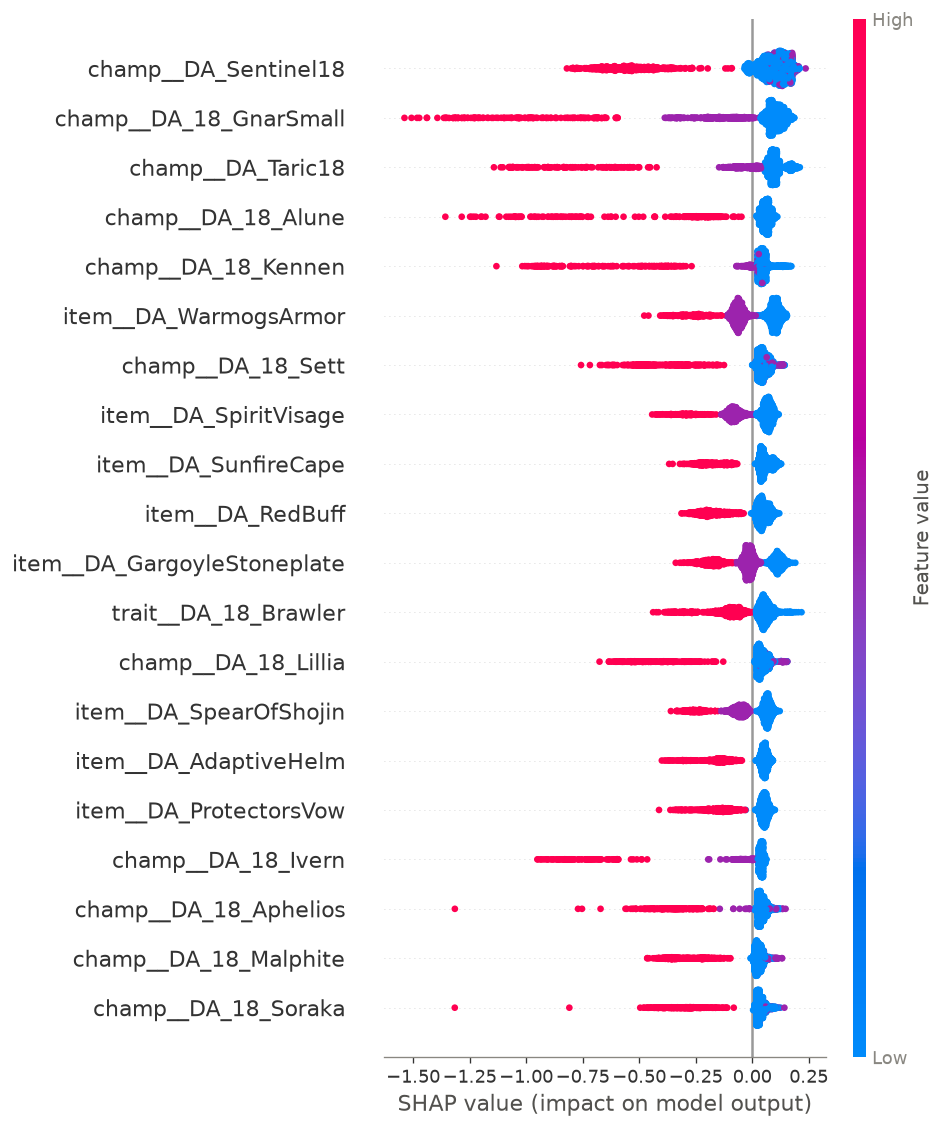

In [25]:
import shap
shap.summary_plot(shap_values, sample, max_display=20, show=False)
plt.tight_layout()
plt.show()

Specific champions and items rank above traits, as in Set 17. Many of these columns also track board
size (3-star units and completed items mostly appear on boards that survived long), so the ranking
doesn't show that champion identity matters. SHAP describes the model, not the game: it doesn't say
what a buff or nerf would change.

### 7.1 Does the lobby's tier change the prediction for the same board?

Section 2.4 can't answer this, but SHAP can: for the same board, does `seed_tier` change the
prediction? To check robustness, the model is refit with 5 seeds.

In [26]:
from modeling.explain_model import breakdown_across_seeds, mae_without_column

tier_ablation = mae_without_column(X_train, y_train, X_test, y_test, "seed_tier")
print(f"Test MAE with seed_tier: {tier_ablation['mae_with']:.3f} | without: {tier_ablation['mae_without']:.3f}")

# Mean SHAP of seed_tier per tier, for 5 seeds (model refit + new SHAP sample each time)
breakdown_across_seeds(X_train, y_train, X_test, test_df, "seed_tier").reindex(TIER_ORDER).round(4)

Test MAE with seed_tier: 1.174 | without: 1.190


,mean_over_seeds,std_between_seeds,min,max,same_sign_all_seeds
seed_tier,,,,,
IRON,-0.0078,0.0123,-0.0277,0.0048,False
BRONZE,-0.4053,0.0115,-0.4197,-0.3899,True
SILVER,-0.0131,0.0114,-0.0302,0.0018,False
GOLD,-0.0144,0.0113,-0.0300,0.0007,False
PLATINUM,-0.0161,0.0113,-0.0311,-0.0003,True
EMERALD,-0.0178,0.0111,-0.0316,-0.0011,True
DIAMOND,-0.0171,0.0122,-0.0311,0.0022,False
MASTER,-0.0187,0.0104,-0.0311,-0.0028,True
GRANDMASTER,-0.0158,0.0106,-0.0263,0.0012,False


Removing `seed_tier` raises test MAE from 1.174 to 1.190, a small gain. Since `seed_tier` is the same
for all 8 players of a lobby, it can only shift a whole lobby's predictions up or down: it adjusts how
the board-based prediction is calibrated in each tier, and can't tell players apart, so it can't
measure skill. The per-tier values aren't interpretable either: half of the tiers change sign between
seeds, and Bronze (-0.41 here) was +0.10 when `gold_left` was still a feature, so its value depends on
which other columns the model has. It comes from an interaction learned on 999 Bronze training
matches, not from a stable tier effect.

## 8. Error analysis

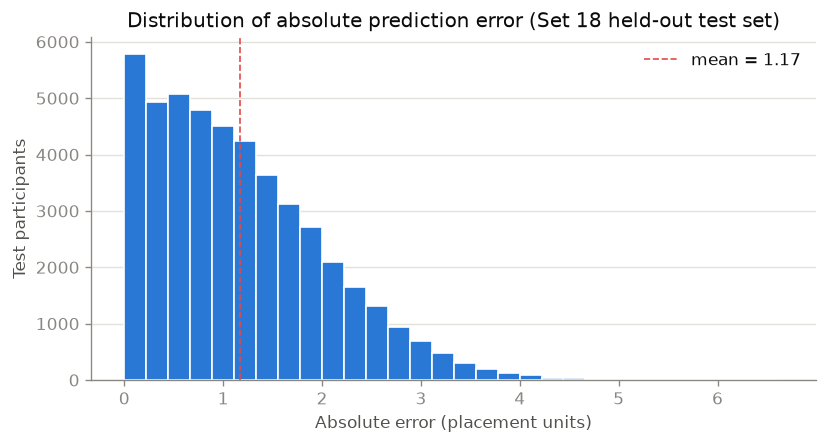

Share of predictions within 1 placement of the truth: 49.1%
Share of predictions off by more than 3 placements:   3.4%


In [27]:
test_errors = test_df.assign(
    pred=pred_test,
    pred_raw=model.predict(X_test),
    abs_error=np.abs(test_df["placement"].values - pred_test),
    signed_error=pred_test - test_df["placement"].values,
)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(test_errors["abs_error"], bins=30, color=COLOR_BLUE, edgecolor="white")
ax.axvline(test_errors["abs_error"].mean(), color=COLOR_RED, linestyle="--", linewidth=1,
           label=f"mean = {test_errors['abs_error'].mean():.2f}")
ax.set_xlabel("Absolute error (placement units)")
ax.set_ylabel("Test participants")
ax.set_title("Distribution of absolute prediction error (Set 18 held-out test set)")
ax.legend(frameon=False)
ax.grid(axis="y")
plt.tight_layout()
plt.show()

print(f"Share of predictions within 1 placement of the truth: {(test_errors['abs_error'] <= 1).mean():.1%}")
print(f"Share of predictions off by more than 3 placements:   {(test_errors['abs_error'] > 3).mean():.1%}")

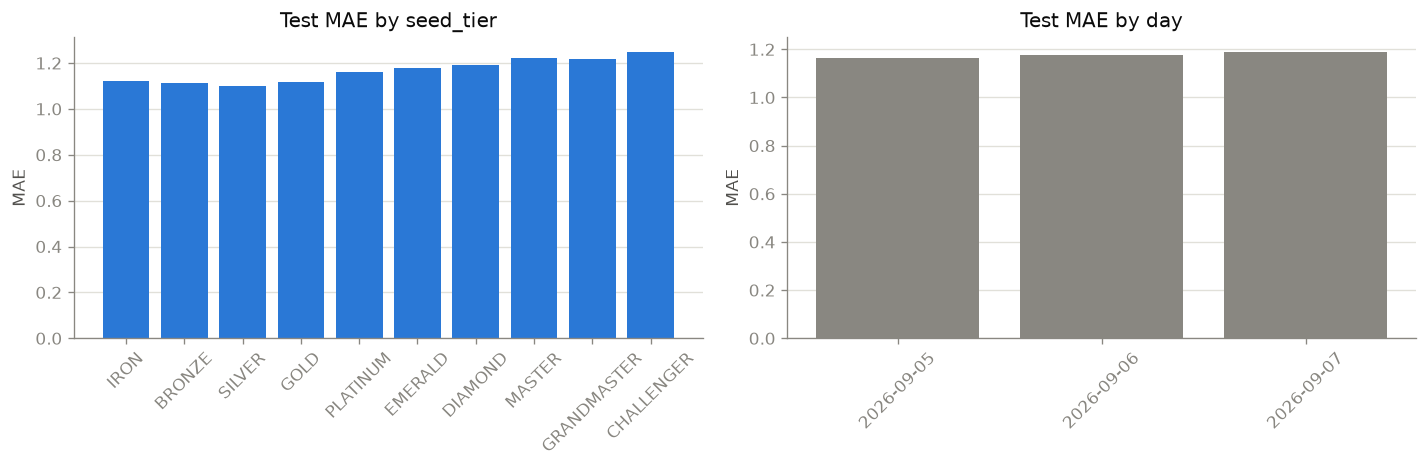

MAE by tier (n = sample size, small tiers are noisy):
              mean  count
seed_tier                
IRON         1.122   1056
BRONZE       1.113   1792
SILVER       1.100   2520
GOLD         1.119   4096
PLATINUM     1.160   8352
EMERALD      1.179  10224
DIAMOND      1.190   9152
MASTER       1.221   4552
GRANDMASTER  1.220   2824
CHALLENGER   1.250   2224

MAE by day:
             mean  count
day                     
2026-09-05  1.166  17944
2026-09-06  1.177  24464
2026-09-07  1.191   4384


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

mae_by_tier = test_errors.groupby("seed_tier")["abs_error"].agg(["mean", "count"])
mae_by_tier = mae_by_tier.reindex([t for t in TIER_ORDER if t in mae_by_tier.index]).dropna()
axes[0].bar(mae_by_tier.index, mae_by_tier["mean"], color=COLOR_BLUE)
axes[0].set_title("Test MAE by seed_tier")
axes[0].set_ylabel("MAE")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(axis="y")

test_errors_dated = test_errors.assign(day=pd.to_datetime(test_errors["game_datetime"], unit="ms").dt.date)
mae_by_day = test_errors_dated.groupby("day")["abs_error"].agg(["mean", "count"]).sort_index()
axes[1].bar(mae_by_day.index.astype(str), mae_by_day["mean"], color=COLOR_MUTED)
axes[1].set_title("Test MAE by day")
axes[1].set_ylabel("MAE")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(axis="y")

plt.tight_layout()
plt.show()

print("MAE by tier (n = sample size, small tiers are noisy):")
print(mae_by_tier.round(3).to_string())
print("\nMAE by day:")
print(mae_by_day.round(3).to_string())

In [29]:
from features.build_feature_matrix import board_counters

# Does board size separate players less in high tiers?
model_rows = pd.concat([train_df, test_df])
board_by_tier = model_rows[["match_id", "seed_tier", "placement"]].join(board_counters(model_rows)[["sum_star"]])
pd.DataFrame({
    "within_match_std_sum_star": board_by_tier.groupby(["seed_tier", "match_id"])["sum_star"].std()
                                              .groupby("seed_tier").mean(),
    "corr_sum_star_placement": board_by_tier.groupby("seed_tier")[["sum_star", "placement"]]
                                            .apply(lambda g: g.corr().iloc[0, 1]),
}).reindex(TIER_ORDER).round(3)

,within_match_std_sum_star,corr_sum_star_placement
seed_tier,,
IRON,3.304,-0.700
BRONZE,3.141,-0.702
SILVER,3.134,-0.677
GOLD,2.967,-0.637
PLATINUM,2.886,-0.619
EMERALD,2.792,-0.609
DIAMOND,2.727,-0.600
MASTER,2.712,-0.593
GRANDMASTER,2.672,-0.594


Error grows with tier, from 1.10 in Silver to 1.25 in Challenger, and barely moves across test days
(1.17 to 1.19). The table above suggests why: in high tiers, boards in the same lobby are closer in
size (standard deviation of total stars 2.6 against 3.1 to 3.3 in Iron to Silver) and board size
follows placement less closely (correlation -0.56 against -0.70). Since the model mostly reads board
size, it has less to go on in high-elo lobbies.

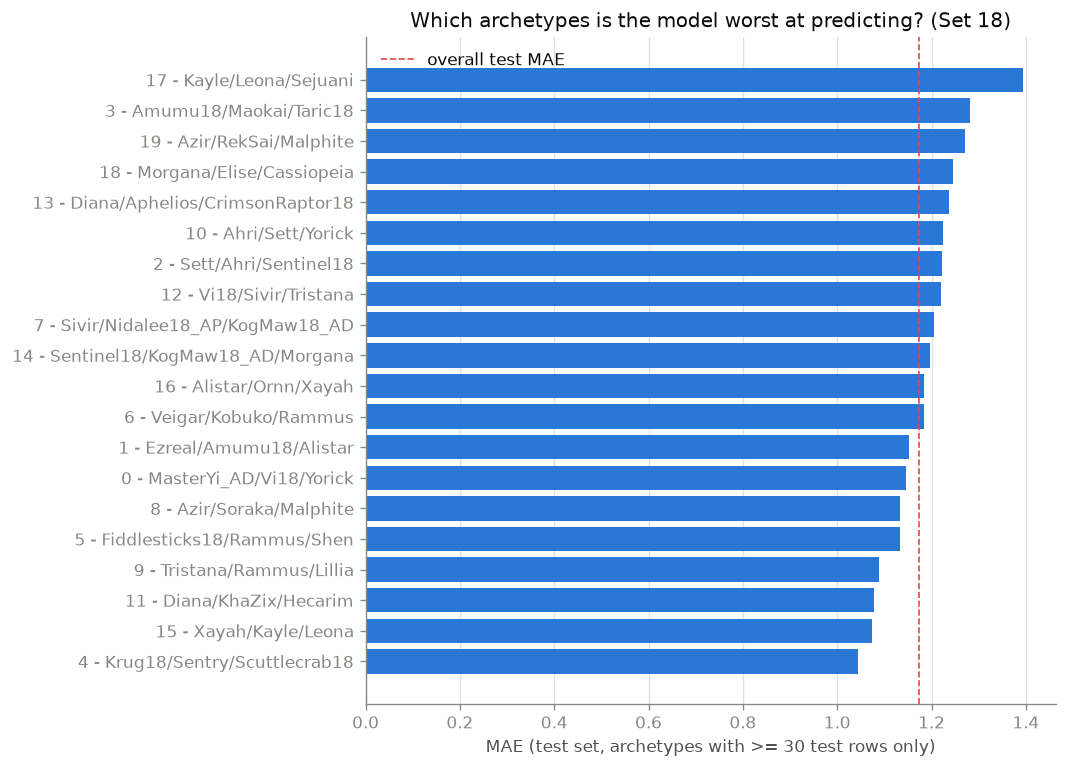

,n,mae,avg_signed_error
17 - Kayle/Leona/Sejuani,2263,1.394,0.243
3 - Amumu18/Maokai/Taric18,1621,1.281,-0.213
19 - Azir/RekSai/Malphite,1306,1.270,0.188
18 - Morgana/Elise/Cassiopeia,904,1.245,-0.214
13 - Diana/Aphelios/CrimsonRaptor18,2566,1.238,-0.057
10 - Ahri/Sett/Yorick,1651,1.224,-0.146
2 - Sett/Ahri/Sentinel18,1778,1.222,-0.207
12 - Vi18/Sivir/Tristana,1871,1.220,-0.035
7 - Sivir/Nidalee18_AP/KogMaw18_AD,3592,1.206,0.055
14 - Sentinel18/KogMaw18_AD/Morgana,1118,1.197,-0.010


In [30]:
error_with_archetype = test_errors.merge(
    contest_df[["participant_id", "archetype_cluster", "contest_bucket"]],
    on="participant_id", how="left",
)

mae_by_archetype = error_with_archetype.groupby("archetype_cluster").agg(
    n=("participant_id", "count"), mae=("abs_error", "mean"), avg_signed_error=("signed_error", "mean"),
)
mae_by_archetype = mae_by_archetype[mae_by_archetype["n"] >= 30]
mae_by_archetype.index = [short_board_label(cid) for cid in mae_by_archetype.index]
mae_by_archetype = mae_by_archetype.sort_values("mae", ascending=False)

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(mae_by_archetype.index[::-1], mae_by_archetype["mae"][::-1], color=COLOR_BLUE)
ax.axvline(test_errors["abs_error"].mean(), color=COLOR_RED, linestyle="--", linewidth=1,
           label="overall test MAE")
ax.set_xlabel("MAE (test set, archetypes with >= 30 test rows only)")
ax.set_title("Which archetypes is the model worst at predicting? (Set 18)")
ax.legend(frameon=False)
ax.grid(axis="x")
plt.tight_layout()
plt.show()

mae_by_archetype.round(3)

In [31]:
mae_by_contest = error_with_archetype.groupby("contest_bucket")["abs_error"].agg(mean="mean", std="std", n="count")
mae_by_contest["ci95"] = 1.96 * mae_by_contest["std"] / np.sqrt(mae_by_contest["n"])
mae_by_contest = mae_by_contest.reindex(["0 (uncontested)", "1 other", "2+ others"])
mae_by_contest[["mean", "ci95", "n"]]

,mean,ci95,n
contest_bucket,,,
0 (uncontested),1.193772,0.009609,32156
1 other,1.133682,0.015017,11878
2+ others,1.119422,0.030357,2758


Errors concentrate on a few archetypes, led by Kayle/Leona/Sejuani (17, MAE 1.39);
Azir/RekSai/Malphite (19, 1.27), the archetype with the worst average placement, is third. Contrary to what I
expected, uncontested boards are the hardest to predict (1.19 against 1.13 with one other, CIs don't
overlap), probably because contested archetypes are popular ones the model has seen more often.

In [32]:
worst_cases = error_with_archetype.sort_values("abs_error", ascending=False).head(10)
display(worst_cases[["participant_id", "seed_tier", "archetype_cluster", "contest_bucket",
             "placement", "pred_raw", "pred", "abs_error"]].assign(
    archetype_cluster=lambda d: d["archetype_cluster"].map(
        lambda cid: short_board_label(cid) if pd.notna(cid) else "n/a"
    ),
).round(2))

big_errors = error_with_archetype[error_with_archetype["abs_error"] >= 6]
print(f"Test rows off by 6 places or more: {len(big_errors)}, of which archetype 19: "
      f"{(big_errors['archetype_cluster'] == 19).sum()} "
      f"(archetype 19 is {(error_with_archetype['archetype_cluster'] == 19).mean():.1%} of the test set)")

,participant_id,seed_tier,archetype_cluster,contest_bucket,placement,pred_raw,pred,abs_error
35376,254521,PLATINUM,19 - Azir/RekSai/Malphite,0 (uncontested),1,7.66,7.66,6.66
1248,2865,EMERALD,19 - Azir/RekSai/Malphite,0 (uncontested),1,7.36,7.36,6.36
33320,245697,PLATINUM,19 - Azir/RekSai/Malphite,1 other,1,7.20,7.20,6.20
20041,176986,DIAMOND,8 - Azir/Soraka/Malphite,0 (uncontested),2,8.43,8.00,6.00
24817,203370,EMERALD,19 - Azir/RekSai/Malphite,0 (uncontested),2,9.55,8.00,6.00
31721,238234,EMERALD,19 - Azir/RekSai/Malphite,0 (uncontested),2,9.55,8.00,6.00
22313,188298,DIAMOND,19 - Azir/RekSai/Malphite,0 (uncontested),2,8.57,8.00,6.00
44425,307930,SILVER,19 - Azir/RekSai/Malphite,0 (uncontested),2,8.52,8.00,6.00
34649,252026,PLATINUM,5 - Fiddlesticks18/Rammus/Shen,0 (uncontested),2,8.27,8.00,6.00
42593,297346,SILVER,19 - Azir/RekSai/Malphite,0 (uncontested),2,8.37,8.00,6.00


Test rows off by 6 places or more: 20, of which archetype 19: 15 (archetype 19 is 2.8% of the test set)


**15 of the 20 errors of 6 places or more are archetype 19**, which is only 2.8% of the test set: players
who finished 1st or 2nd but were predicted 7.2 to 9.6 before bounding, across tiers and contest levels.
The model learned that this comp usually loses, and from the final board alone it can't tell a weak
comp from a player who made it work.

## 9. Conclusions

| Question | Answer |
|---|---|
| How well does the final board predict placement? | MAE 1.17 against 2.00, top 4 right 82 to 84%. But five board-size counters do better (1.09): this is mostly a reconstruction of survival. At equal board size, the composition is worth about 0.13 places (0.96 with counters), an upper bound. |
| Does contest hurt placement? | Weakly: +0.30 places per extra player raw, +0.04 within a match at equal board size. An association, probably a lower bound. |
| What does the model rely on? | Champions and items, entangled with board size. `seed_tier` adds a small gain (0.016) that can only shift whole lobbies; its per-tier values aren't stable. |
| Where does it fail? | Rare wins of a usually losing archetype (15 of the 20 errors of 6+ places), uncontested boards, high tiers where boards are closer in size. |
| Does it generalize? | Partly. On 9,908 matches from 18.3, MAE rises from 1.17 to 1.27 while the counters only go from 1.09 to 1.12; the composition gain over the counters holds (0.11). On Set 17 the same pipeline reaches a similar MAE (1.18), but the board-size baselines weren't run there, so this doesn't show that composition knowledge transfers across sets. |

**Limitations.** End-of-game data only (no timeline, no augments). Effects are observational.
`seed_tier` is a lobby-level label. Training covers 12 days of a single patch, and 18.2 is missing.
Clusters have a low silhouette, though they are stable. Bot-filled lobbies are excluded from the model
and from the contest regression, but not from the descriptive sections.

**Next step.** Retrain on 18.1 plus the first days of 18.3 and test on the rest of 18.3, to see
whether the loss on later patches comes from balance changes the model hasn't seen.